### PREPROCESS FILE

In [8]:
import os
import librosa
import soundfile as sf

In [9]:
def resample_and_normalize(audio_path, target_sr=16000):
    audio, original_sr = librosa.load(audio_path, sr=None)
    
    if original_sr != target_sr:
        audio = librosa.resample(audio, orig_sr=original_sr, target_sr=target_sr)
    
    max_amplitude = max(abs(audio))
    normalized_audio = audio / max_amplitude
    
    return normalized_audio, target_sr

In [10]:
def process_audio_files(input_directory, output_directory, target_sr=16000):
    if not os.path.exists(output_directory):
        os.makedirs(output_directory)

    for filename in os.listdir(input_directory):
        if filename.endswith(".wav"):  
            audio_path = os.path.join(input_directory, filename)
            output_path = os.path.join(output_directory, filename)
            
            processed_audio, new_sr = resample_and_normalize(audio_path, target_sr)
            
            sf.write(output_path, processed_audio, new_sr)

In [11]:
input_dir = "./data/Upload to MDS group/Training Dataset/Diagnosis training data/ADReSSo21/diagnosis/train/audio/ad"
output_dir = "./processed/train/ad"
target_sample_rate = 16000  
process_audio_files(input_dir, output_dir, target_sample_rate)

In [12]:
input_dir = "./data/Upload to MDS group/Training Dataset/Diagnosis training data/ADReSSo21/diagnosis/train/audio/cn"
output_dir = "./processed/train/cn"
target_sample_rate = 16000  
process_audio_files(input_dir, output_dir, target_sample_rate)

### EXTRACT FEATURES

In [13]:
import os
import numpy as np
import librosa
import soundfile as sf
import parselmouth

In [14]:
def extract_features_with_stats(audio_path, target_sr=16000):
    # Load the audio file
    audio, sr = librosa.load(audio_path, sr=target_sr)

    # Extract MFCCs
    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    mfcc_stats = {
        "mean": np.mean(mfccs.T, axis=0),
        "min": np.min(mfccs.T, axis=0),
        "max": np.max(mfccs.T, axis=0),
        "std": np.std(mfccs.T, axis=0)
    }

    # Extract Chroma features
    chroma = librosa.feature.chroma_stft(y=audio, sr=sr)
    chroma_stats = {
        "mean": np.mean(chroma.T, axis=0),
        "min": np.min(chroma.T, axis=0),
        "max": np.max(chroma.T, axis=0),
        "std": np.std(chroma.T, axis=0)
    }

    # Extract Spectral Contrast
    spectral_contrast = librosa.feature.spectral_contrast(y=audio, sr=sr)
    spectral_contrast_stats = {
        "mean": np.mean(spectral_contrast.T, axis=0),
        "min": np.min(spectral_contrast.T, axis=0),
        "max": np.max(spectral_contrast.T, axis=0),
        "std": np.std(spectral_contrast.T, axis=0)
    }

    # Extract Formants using Praat Parselmouth
    sound = parselmouth.Sound(audio_path)
    formant_object = sound.to_formant_burg(time_step=0.01)
    num_formants = 5
    formants_stats = {
        "mean": np.zeros(num_formants),
        "min": np.zeros(num_formants),
        "max": np.zeros(num_formants),
        "std": np.zeros(num_formants)
    }
    for i in range(num_formants):
        formant_values = [
            formant_object.get_value_at_time(i + 1, t)
            for t in formant_object.ts()
            if formant_object.get_value_at_time(i + 1, t) != 0
        ]
        if formant_values:
            formants_stats["mean"][i] = np.mean(formant_values)
            formants_stats["min"][i] = np.min(formant_values)
            formants_stats["max"][i] = np.max(formant_values)
            formants_stats["std"][i] = np.std(formant_values)
        else:
            formants_stats["mean"][i] = formants_stats["min"][i] = formants_stats["max"][i] = formants_stats["std"][i] = np.nan

    return {
        "mfcc_stats": mfcc_stats,
        "chroma_stats": chroma_stats,
        "spectral_contrast_stats": spectral_contrast_stats,
        "formants_stats": formants_stats
    }


In [15]:
def process_audio_directory(input_directory, target_sr=16000):
    features_list = []
    for filename in os.listdir(input_directory):
        if filename.endswith(".wav"): 
            audio_path = os.path.join(input_directory, filename)
            features = extract_features_with_stats(audio_path, target_sr=target_sr)
            features_list.append({
                "filename": filename,
                **features
            })
    return features_list

In [17]:
input_dir = "./processed/train/ad"
audio_features_AD = process_audio_directory(input_dir, target_sr=16000)

In [18]:
input_dir = "./processed/train/cn"
audio_features_CN = process_audio_directory(input_dir, target_sr=16000)

###  PLOTS

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [23]:
ad_mfcc_means = [features['mfcc_stats']['mean'] for features in audio_features_AD]
control_mfcc_means = [features['mfcc_stats']['mean'] for features in audio_features_CN]

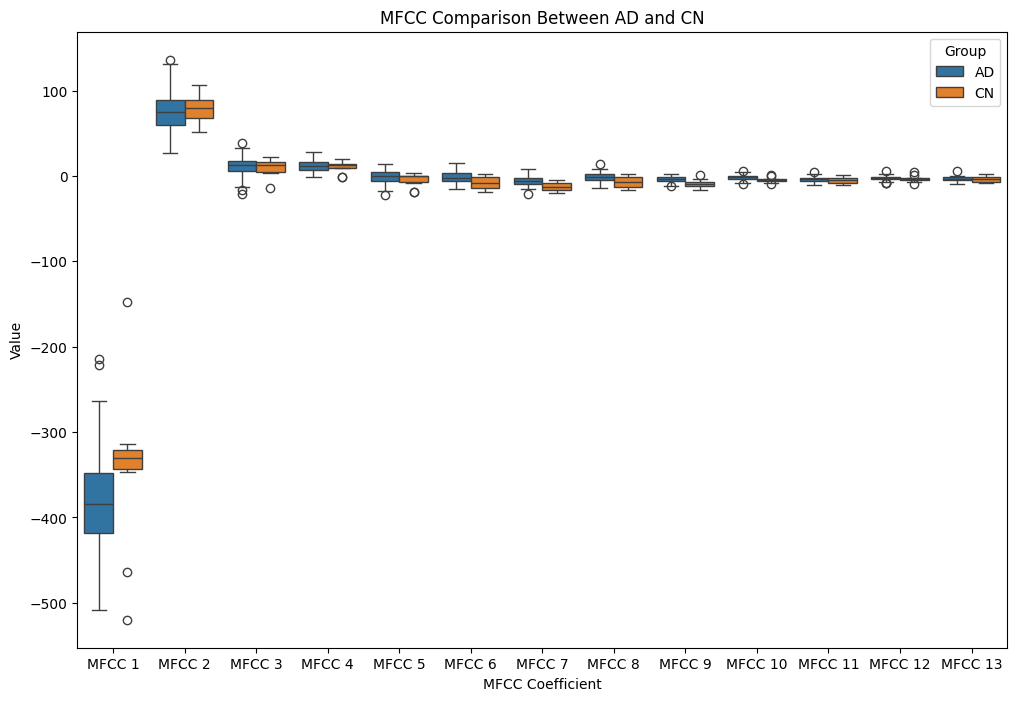

In [28]:
ad_df = pd.DataFrame(ad_mfcc_means, columns=[f'MFCC {i + 1}' for i in range(len(ad_mfcc_means[0]))])
control_df = pd.DataFrame(control_mfcc_means, columns=[f'MFCC {i + 1}' for i in range(len(control_mfcc_means[0]))])

ad_df['Group'] = 'AD'
control_df['Group'] = 'CN'

combined_df = pd.concat([ad_df, control_df], ignore_index=True)

melted_df = pd.melt(combined_df, id_vars='Group', var_name='MFCC', value_name='Value')

plt.figure(figsize=(12, 8))
sns.boxplot(x='MFCC', y='Value', hue='Group', data=melted_df)
plt.title('MFCC Comparison Between AD and CN')
plt.xlabel('MFCC Coefficient')
plt.ylabel('Value')
plt.legend(title='Group')
plt.show()


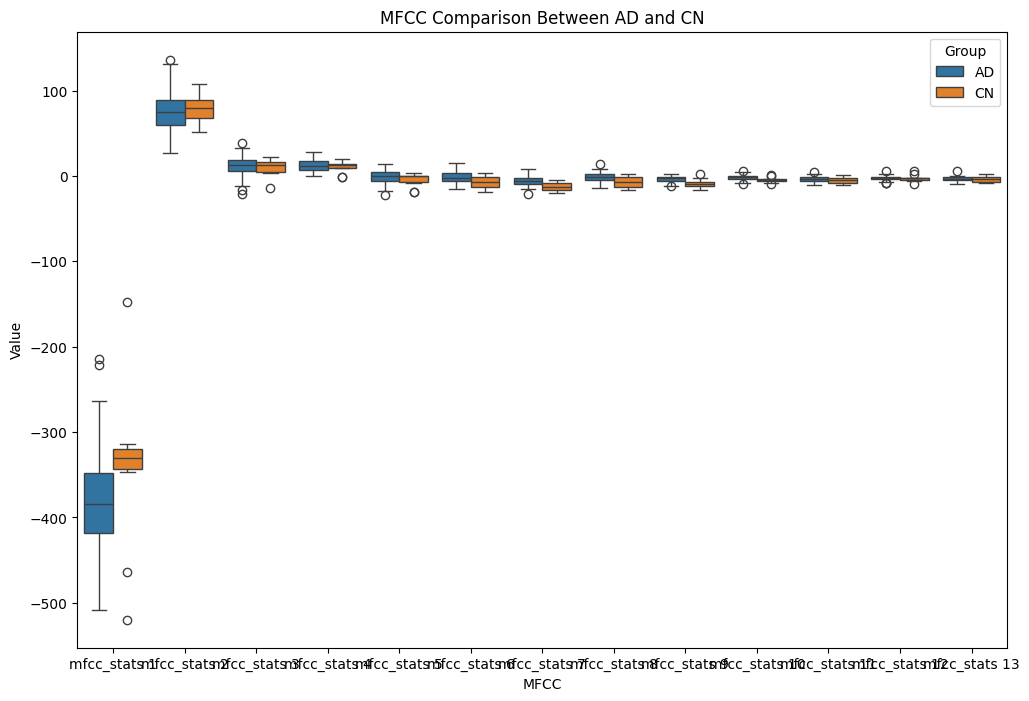

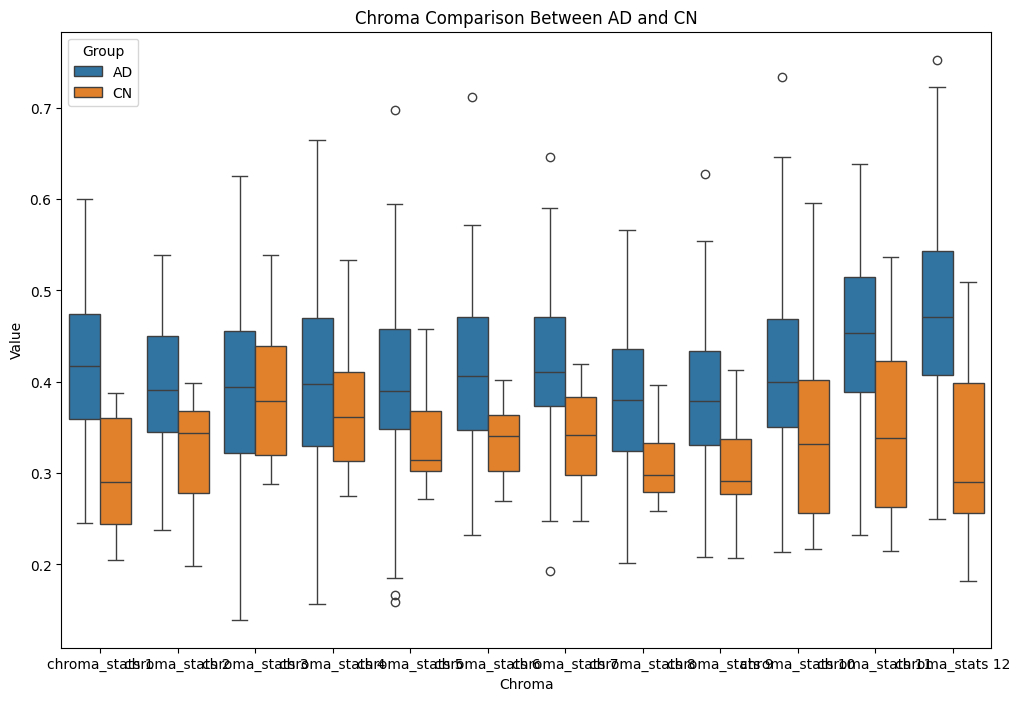

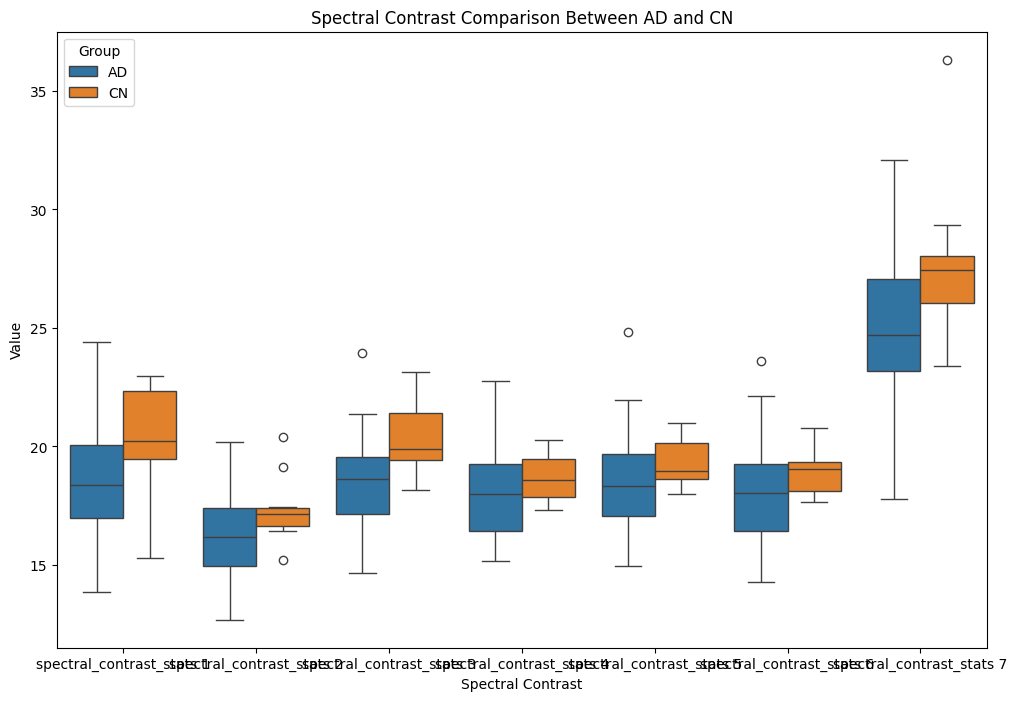

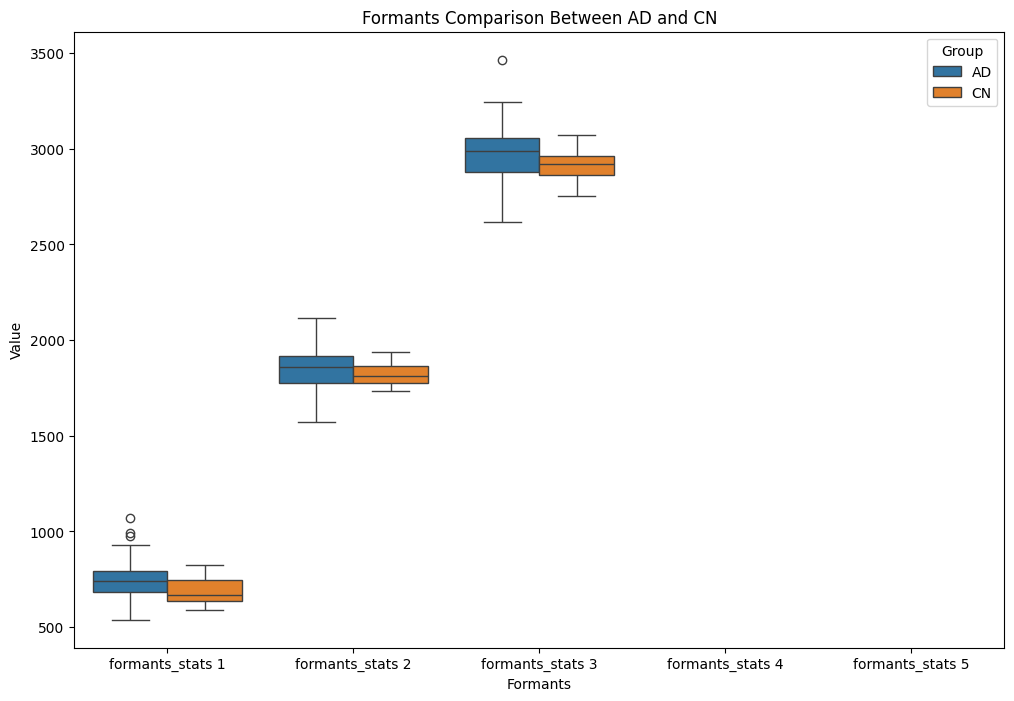

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def create_feature_dataframe(features_list, feature_name, group_label):
    feature_data = [features[feature_name]['mean'] for features in features_list]
    num_features = len(feature_data[0])
    columns = [f'{feature_name} {i + 1}' for i in range(num_features)]
    df = pd.DataFrame(feature_data, columns=columns)
    df['Group'] = group_label
    return df

ad_mfcc_df = create_feature_dataframe(audio_features_AD, 'mfcc_stats', 'AD')
control_mfcc_df = create_feature_dataframe(audio_features_CN, 'mfcc_stats', 'CN')
ad_chroma_df = create_feature_dataframe(audio_features_AD, 'chroma_stats', 'AD')
control_chroma_df = create_feature_dataframe(audio_features_CN, 'chroma_stats', 'CN')
ad_spectral_df = create_feature_dataframe(audio_features_AD, 'spectral_contrast_stats', 'AD')
control_spectral_df = create_feature_dataframe(audio_features_CN, 'spectral_contrast_stats', 'CN')
ad_formants_df = create_feature_dataframe(audio_features_AD, 'formants_stats', 'AD')
control_formants_df = create_feature_dataframe(audio_features_CN, 'formants_stats', 'CN')

combined_mfcc_df = pd.concat([ad_mfcc_df, control_mfcc_df], ignore_index=True)
combined_chroma_df = pd.concat([ad_chroma_df, control_chroma_df], ignore_index=True)
combined_spectral_df = pd.concat([ad_spectral_df, control_spectral_df], ignore_index=True)
combined_formants_df = pd.concat([ad_formants_df, control_formants_df], ignore_index=True)

def plot_feature_comparison(df, feature_name):
    melted_df = pd.melt(df, id_vars='Group', var_name=f'{feature_name}', value_name='Value')
    plt.figure(figsize=(12, 8))
    sns.boxplot(x=f'{feature_name}', y='Value', hue='Group', data=melted_df)
    plt.title(f'{feature_name} Comparison Between AD and CN')
    plt.xlabel(f'{feature_name}')
    plt.ylabel('Value')
    plt.legend(title='Group')
    plt.show()

# Plot each feature set
plot_feature_comparison(combined_mfcc_df, 'MFCC')
plot_feature_comparison(combined_chroma_df, 'Chroma')
plot_feature_comparison(combined_spectral_df, 'Spectral Contrast')
plot_feature_comparison(combined_formants_df, 'Formants')
